<a href="https://colab.research.google.com/github/yokubbekovas/7november/blob/main/Tactile_Midterm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 43: Edge-AI Haptic Surface Recognition for Robotic Grippers
**Course:** Artificial Intelligence
**Stage:** Midterm evaluation
**Student:** Shakhzoda Ekubbekova

**Goal:** Classify the material surface texture from tactile sensor signals during sliding contact (the slip state detection is planned for the final stage).

**Planned pipeline:** data loading → preprocessing → baseline classifier (SVM) → autoencoder + SVM → evaluation (accuracy, confusion matrix).

**Environment:** Google Colab, Python, PyTorch, scikit-learn.

## Step 1. Dataset download

For this project I use the open BioTac sliding dataset (BioTac-20) published by Gao et al. (IROS 2020). It contains tactile recordings of a BioTac sensor sliding over 20 different materials, with 50 samples per material.

Note: the BioTac sensor has 19 electrodes and is not a 16x16 piezoelectric matrix as in the project description. The data will be adapted to the project setting, and this difference will be reported as a limitation.

The cell below clones the dataset repository from GitHub into the Colab environment.

In [ ]:
# Скачиваем датасет с GitHub в Colab
!git clone https://github.com/dexrob/BioTac_slide_20_50.git

# Смотрим, что внутри
!ls BioTac_slide_20_50

Cloning into 'BioTac_slide_20_50'...
remote: Enumerating objects: 8143, done.
remote: Counting objects: 100% (118/118), done.
remote: Compressing objects: 100% (46/46), done.
remote: Total 8143 (delta 74), reused 115 (delta 72), pack-reused 8025 (from 1)
Receiving objects: 100% (8143/8143), 240.07 MiB | 15.31 MiB/s, done.
Resolving deltas: 100% (79/79), done.
Updating files: 100% (8042/8042), done.
compiled_data		  matx_collage.png  README.md
Material_properties.docx  raw_data	    tas_utils_bs.py


## Step 2. Dataset structure inspection

Before writing any model code, I read the dataset README and inspect the folder structure. This is needed to understand the file format, the meaning of the data columns, and how the material labels are stored.

The cell below prints the README, lists the files in `compiled_data` and shows the contents of `raw_data`.

In [ ]:
# 1) Читаем описание датасета
print(open("BioTac_slide_20_50/README.md").read())

print("="*60)

# 2) Что лежит в compiled_data
!ls -la BioTac_slide_20_50/compiled_data

print("="*60)

# 3) Что лежит в raw_data (первые 15 элементов) и сколько всего
!ls BioTac_slide_20_50/raw_data | head -15
!ls BioTac_slide_20_50/raw_data | wc -l

# BioTac_slide_20_50
This repository contains tactile data and material description for texture classification, supplementary to the paper "Supervised  Autoencoder  Joint  Learning  on  Heterogeneous  TactileSensory  Data:  Improving  Material  Classification  Performance", R. Gao et al.

We have included both the raw data and the compiled data here. The raw data includes a comprehensive range of modalities, provided by both tactile sensors and the robot arm. The compiled data includes purely the sensor data that are used in the abovementioned paper and have already been splitted in to train/validation/test sets.

## Dataset description
This dataset concerns with 20 classes named with `mat + x`, where `x` is an index number. A snapshot of each corresponding material is shown below and the detailed description for each material can be found in `material_properties` text file by the name index or two-letter code.
![material_snaposhots](matx_collage.png "Snapshots of 20 materials")
<br/>


## Step 3. Loading and checking the data

The folder `compiled_data` contains pre-processed arrays in NumPy format (`.npy`). Only the BioTac files (`bio_*`) and their labels (`labels_*`) are used in this project; the `icub_*` files belong to another sensor and are not needed.

I load the full training set (`bio_trainAll`) and the test set (`bio_test`), and check: array shapes, data type, number of classes, number of samples per class, value range, and missing values (NaN). This confirms that the data is correct before any modelling.

Finally, I plot the signals of one sample to see what the tactile signal looks like.

X_train: (800, 19, 400) float32
y_train: (800,) int64
X_test:  (200, 19, 400)
y_test:  (200,)
Classes: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19]
Samples per class (train): [40 40 40 40 40 40 40 40 40 40 40 40 40 40 40 40 40 40 40 40]
Min / Max value: -128.0 127.0
Has NaN: False


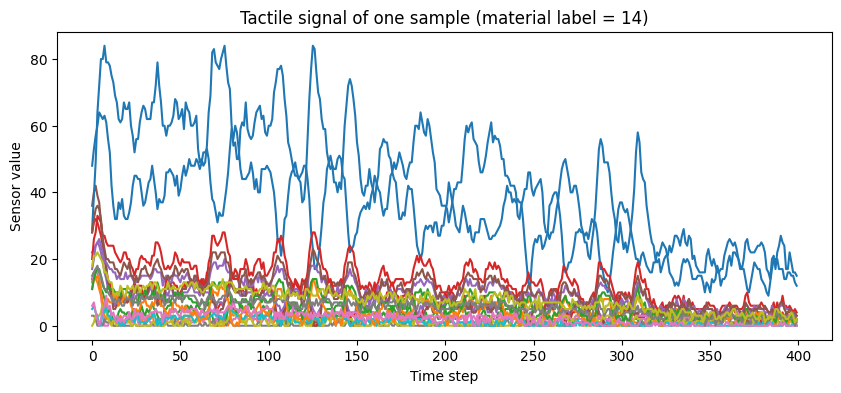

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

path = "BioTac_slide_20_50/compiled_data/"

X_train = np.load(path + "bio_trainAll.npy")
y_train = np.load(path + "labels_trainAll.npy")
X_test  = np.load(path + "bio_test.npy")
y_test  = np.load(path + "labels_test.npy")

print("X_train:", X_train.shape, X_train.dtype)
print("y_train:", y_train.shape, y_train.dtype)
print("X_test: ", X_test.shape)
print("y_test: ", y_test.shape)

classes, counts = np.unique(y_train, return_counts=True)
print("Classes:", classes)
print("Samples per class (train):", counts)

print("Min / Max value:", X_train.min(), X_train.max())
print("Has NaN:", np.isnan(X_train).any())

# Plot all channels of the first sample
sample = X_train[0]
if sample.shape[0] < sample.shape[1]:   # make shape (time, channels)
    sample = sample.T
plt.figure(figsize=(10, 4))
plt.plot(sample)
plt.title(f"Tactile signal of one sample (material label = {y_train[0]})")
plt.xlabel("Time step")
plt.ylabel("Sensor value")
plt.show()

## Step 4. Baseline: hand-crafted features + SVM

As a first baseline, I compress every sample (19 electrodes x 400 time steps) into 95 simple statistical features: for each electrode, the mean, standard deviation, maximum, minimum, and the mean absolute change between consecutive time steps (a rough measure of signal roughness, which is related to surface texture).

The features are standardized (zero mean, unit variance), because electrodes have very different amplitudes. Then an SVM classifier with an RBF kernel is trained on the training set and evaluated on the test set.

Metrics: test accuracy, confusion matrix, and prediction time per sample. This baseline will later be compared with the Convolutional Autoencoder + SVM model.

Feature shape: (800, 95) (200, 95)
Training time: 0.11 s
Test accuracy: 99.0 %
Prediction time: 0.149 ms per sample (on Colab CPU)


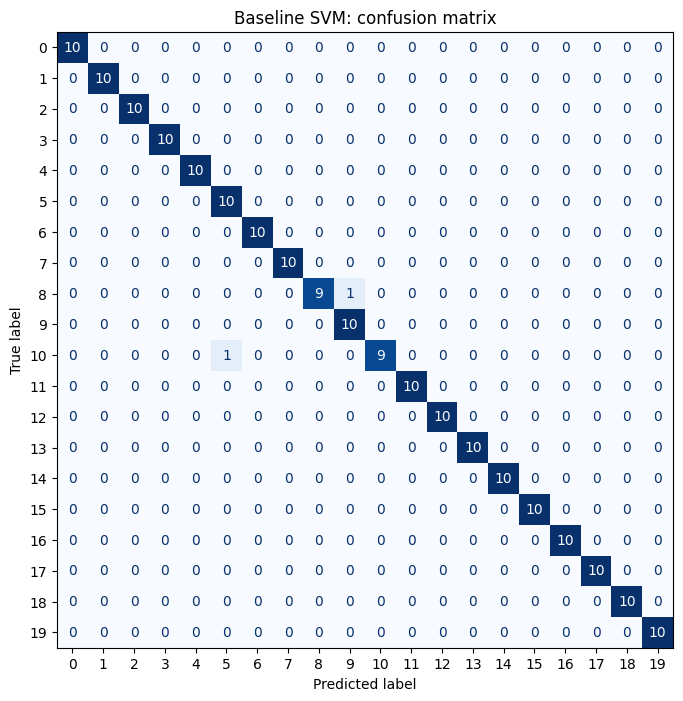

In [4]:
import time
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

def extract_features(X):
    mean = X.mean(axis=2)
    std  = X.std(axis=2)
    mx   = X.max(axis=2)
    mn   = X.min(axis=2)
    diff = np.abs(np.diff(X, axis=2)).mean(axis=2)
    return np.concatenate([mean, std, mx, mn, diff], axis=1)

F_train = extract_features(X_train)
F_test  = extract_features(X_test)
print("Feature shape:", F_train.shape, F_test.shape)

# Standardize (fit only on training data)
scaler = StandardScaler()
F_train_s = scaler.fit_transform(F_train)
F_test_s  = scaler.transform(F_test)

# Train SVM
t0 = time.time()
svm = SVC(kernel="rbf", C=10, gamma="scale")
svm.fit(F_train_s, y_train)
print(f"Training time: {time.time() - t0:.2f} s")

# Evaluate
t0 = time.time()
y_pred = svm.predict(F_test_s)
ms_per_sample = (time.time() - t0) / len(F_test_s) * 1000

print(f"Test accuracy: {accuracy_score(y_test, y_pred) * 100:.1f} %")
print(f"Prediction time: {ms_per_sample:.3f} ms per sample (on Colab CPU)")

# Confusion matrix
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, cmap="Blues", colorbar=False)
plt.title("Baseline SVM: confusion matrix")
plt.show()